# Issue 4 — ES futures events

This notebook loads the local event files generated from the Issue 3 MBP-1 cache. It compares our original reversal filter with the unfiltered version, and shows how the two observation-window definitions affect the sample. Run `python scripts/detect_events.py` before opening the notebook. The large Parquet files stay under `data/processed/` and are not committed.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
REPORT = ROOT / "reports" / 'issue4_report'
PROCESSED = ROOT / 'data' / 'processed' / 'events'
summary = pd.read_csv(REPORT / 'event_counts.csv')
display(summary)

,date,variant,source_records,candidate_count,selected_cluster_count,single_move_cluster_count,excluded_multi_move_clusters,single_update_count,excluded_after_single_move,excluded_after_window,final_event_count,event_count,sub_tick,single_tick,multi_tick,raw_window_truncated,tick_window_truncated
0,2026-10-05,baseline,3646277,158413,67544,46683,20861,46683,0,0,46683,46683,44047,2535,101,27360,2529
1,2026-10-05,unfiltered,3646277,158413,158413,158413,0,158413,0,0,158413,158413,152520,5760,133,119946,17615
2,2026-10-06,baseline,3669065,141898,55656,35990,19666,35990,0,0,35990,35990,33734,2212,44,22129,2140
3,2026-10-06,unfiltered,3669065,141898,141898,141898,0,141898,0,0,141898,141898,136640,5195,63,109784,16124
4,2026-10-07,baseline,4547488,217693,89318,61741,27577,61741,0,0,61741,61741,59539,2132,70,36650,2708
5,2026-10-07,unfiltered,4547488,217693,217693,217693,0,217693,0,0,217693,217693,211844,5729,120,167130,21284
6,2026-10-08,baseline,6148295,343533,155551,113791,41760,113791,0,0,113791,113791,110210,3420,161,70074,3567
7,2026-10-08,unfiltered,6148295,343533,343533,343533,0,343533,0,0,343533,343533,335792,7485,256,261327,23459
8,2026-10-09,baseline,3299223,150865,64260,44280,19980,44280,0,0,44280,44280,42286,1942,52,25769,2050
9,2026-10-09,unfiltered,3299223,150865,150865,150865,0,150865,0,0,150865,150865,146242,4515,108,114052,15227


## Event counts and censoring

The default series keeps single price updates that pass the retrospective 250,000 ns cluster filter. The `unfiltered` series uses a zero clustering gap. The original observation window ends at the next raw midpoint move. The longer alternative ends at the next raw move of at least one ES tick; it does not prove that the quote remains stale throughout that interval.

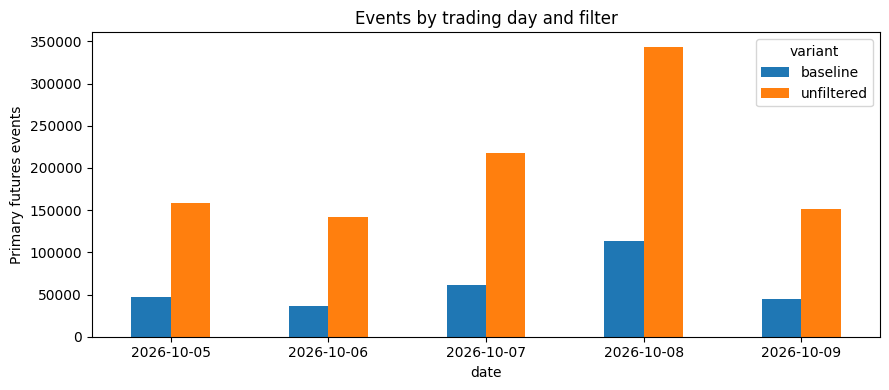

In [2]:
chart = summary.pivot(index='date',columns='variant',values='event_count')
ax = chart.plot(kind='bar',figsize=(9,4),rot=0)
ax.set_ylabel('Primary futures events')
ax.set_title('Events by trading day and filter')
plt.tight_layout()
plt.show()

In [3]:
rows=[]
for day in sorted(summary.date.unique()):
    for variant in ('baseline','unfiltered'):
        name='events.parquet' if variant=='baseline' else 'events_unfiltered.parquet'
        path=PROCESSED/day.replace('-','')/name
        if not path.exists():
            continue
        e=pd.read_parquet(path,columns=['size_class','observation_duration_ns','observation_duration_tick_ns','observation_end_reason','observation_end_tick_reason'])
        rows.append({'date':day,'variant':variant,'events':len(e),'moves_ge_1_tick':int(e.size_class.isin(['single_tick','multi_tick']).sum()),'median_raw_window_ns':e.observation_duration_ns.median(),'median_tick_window_ns':e.observation_duration_tick_ns.median(),'raw_truncation_rate':e.observation_end_reason.eq('next_price_move').mean(),'tick_truncation_rate':e.observation_end_tick_reason.eq('next_tick_move').mean()})
windows=pd.DataFrame(rows)
display(windows)
windows.to_csv(REPORT/'window_comparison.csv',index=False)

,date,variant,events,moves_ge_1_tick,median_raw_window_ns,median_tick_window_ns,raw_truncation_rate,tick_truncation_rate
0,2026-10-05,baseline,46683,2636,3520548.0,10000000.0,0.586081,0.054174
1,2026-10-05,unfiltered,158413,5893,273226.0,10000000.0,0.757173,0.111197
2,2026-10-06,baseline,35990,2256,1422082.0,10000000.0,0.614865,0.059461
3,2026-10-06,unfiltered,141898,5258,252395.0,10000000.0,0.773683,0.113631
4,2026-10-07,baseline,61741,2202,3244946.0,10000000.0,0.593609,0.043861
5,2026-10-07,unfiltered,217693,5849,264282.0,10000000.0,0.767733,0.097771
6,2026-10-08,baseline,113791,3581,3863984.0,10000000.0,0.615813,0.031347
7,2026-10-08,unfiltered,343533,7741,293190.0,10000000.0,0.760704,0.068287
8,2026-10-09,baseline,44280,1994,3662065.0,10000000.0,0.581956,0.046296
9,2026-10-09,unfiltered,150865,4623,271786.0,10000000.0,0.755987,0.100931


## Notes

All event timestamps use `ts_event` in UTC nanosecond precision. The default series is selected using later information about reversals, so it should not be interpreted as an implementable real-time trading signal. Downstream opportunity rates should show all-event and ≥1-tick denominators separately. See `docs/event_definition.md` for full definitions.